# NIFTY 50 Direction Prediction: a Pre-Market Model
**Harshul Saini & Vishesh Gupta**

## The question
Every trading morning at **9:00 AM** (15 minutes before the market opens), we predict:

> **Will NIFTY 50 close today ABOVE yesterday's close?**  UP = 1, DOWN = 0

This is a **binary classification** problem.

## Why we framed it this way
- **Why direction and not price?** If we predict the price, the model just says "today ≈ yesterday". That looks accurate but tells an investor nothing. Direction is the useful part.
- **Why 9:00 AM and not the evening before?** We first tried predicting at 3:30 PM on the previous day. Accuracy was about 52%, which is the same as tossing a coin. The reason: the biggest news for Indian markets arrives **at night**, when the US market trades. At 9:00 AM this news is already known, so we use it. Section 7f proves this with numbers.
- **Why only NIFTY 50?** One index, done properly, is better than many indices done badly. NIFTY 50 is the main Indian index and has clean data.

## The one rule we follow everywhere
**A feature may only use information that is already known at 9:00 AM on the day we predict.** Nothing from the future is allowed. If we break this rule, accuracy looks great in the notebook and fails in real life. This mistake is called **data leakage**.

| Information | When is it known? | Can we use it? |
|---|---|---|
| NIFTY, India VIX, Bank Nifty up to **yesterday's** close | yesterday 3:30 PM | yes |
| US markets (S&P 500, Nasdaq, US VIX), crude oil, USD/INR: last night's close | before about 5:30 AM today | yes |
| Japan (Nikkei) and Hong Kong (Hang Seng) **opening** today | 5:30 AM and 7:00 AM today | yes |
| NIFTY's own opening price today | 9:15 AM | **no** (too late) |
| Anything about today's close | 3:30 PM | **no** (this is the answer) |

## How this notebook is organised
Each section is one required component of the project.

| Section | Component |
|---|---|
| 0 | Data download |
| 1 | Exploratory Data Analysis (EDA) |
| 2 | Feature Derivation |
| 3 | Classification |
| 4 | Regularization |
| 5 | Hyperparameter Tuning |
| 6 | Ensemble Techniques |
| 7 | Performance Analysis |
| 8 | Real-life use: year-by-year check, an honest money check, and the next signal |
| 9 | Conclusion and viva questions |

Every section has the same shape: **what we do and why (and why not something else)** → **code** → **what we found**.

In [1]:
# ===== SETUP: libraries and settings =====
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEED = 42          # fixed random seed, so the notebook gives the same result every time

# 0. Data

**What:** daily prices from Yahoo Finance, from 2015 until today.

**Why these 10 series:**
- **NIFTY 50:** the thing we predict.
- **India VIX:** the "fear index" of the Indian market. High VIX means traders expect big moves.
- **Bank Nifty:** banks are the biggest part of NIFTY, so they often lead it.
- **S&P 500, Nasdaq, US VIX:** the US market. It trades while India sleeps, and India usually follows it the next morning.
- **Crude oil, USD/INR:** India imports most of its oil and pays in dollars, so both matter for Indian companies.
- **Nikkei (Japan), Hang Seng (Hong Kong):** Asian markets that open a few hours before India. They show how Asia is reacting this morning.

**Why Yahoo Finance and not a paid or live API?** It is free, it goes back many years, and daily data is all this problem needs. A live API gives faster data, but it does not give *more* information for a once-a-day prediction.

The data is saved in the `data/` folder. So the notebook gives the same numbers every time it is run. Set `REFRESH_DATA = True` to download the latest prices.

In [2]:
# ===== STEP 0: DOWNLOAD DATA =====
TICKERS = {
    "nifty": "^NSEI", "indiavix": "^INDIAVIX", "banknifty": "^NSEBANK",        # India
    "sp500": "^GSPC", "nasdaq": "^IXIC", "usvix": "^VIX",                      # USA
    "crude": "CL=F", "usdinr": "INR=X",                                        # oil and rupee
    "nikkei": "^N225", "hangseng": "^HSI",                                     # Asia
}
REFRESH_DATA = False      # True = download the latest prices again (do this outside market hours)

os.makedirs("data", exist_ok=True)
raw = {}
for name, ticker in TICKERS.items():
    path = f"data/{name}.csv"
    if REFRESH_DATA or not os.path.exists(path):
        d = yf.download(ticker, start="2015-01-01", auto_adjust=True, progress=False)
        d.columns = d.columns.get_level_values(0)
        d.dropna(subset=["Close"]).to_csv(path)
    raw[name] = pd.read_csv(path, index_col=0, parse_dates=True)
    print(f"{name:10s} {ticker:10s} {len(raw[name]):5d} days   {raw[name].index.min().date()} to {raw[name].index.max().date()}")

nifty = raw["nifty"].copy()
nifty.tail()

nifty      ^NSEI       2920 days   2015-01-02 to 2026-11-12
indiavix   ^INDIAVIX   2909 days   2015-01-01 to 2026-11-12
banknifty  ^NSEBANK    2925 days   2015-01-01 to 2026-11-12
sp500      ^GSPC       2985 days   2015-01-02 to 2026-11-13
nasdaq     ^IXIC       2985 days   2015-01-02 to 2026-11-13
usvix      ^VIX        2987 days   2015-01-02 to 2026-11-13
crude      CL=F        2985 days   2015-01-02 to 2026-11-13
usdinr     INR=X       3089 days   2015-01-01 to 2026-11-13
nikkei     ^N225       2897 days   2015-01-05 to 2026-11-12
hangseng   ^HSI        2919 days   2015-01-02 to 2026-11-12


,Close,High,Low,Open,Volume
Date,,,,,
2026-11-05,24536.599609,24579.900391,24296.300781,24378.050781,534600
2026-11-06,25030.349609,25030.349609,24388.050781,24538.199219,491000
2026-11-09,25044.650391,25084.050781,24838.750000,25076.400391,406200
2026-11-11,25255.050781,25424.349609,25095.349609,25337.800781,458000
2026-11-12,25299.349609,25384.800781,25142.949219,25213.500000,349200


# 1. Exploratory Data Analysis (EDA)

**What:** before building any model, we look at the data.

**Why:** every later decision should come from something we saw here. We ask six questions:

| # | Question | Why it matters |
|---|---|---|
| 1a | Is the data clean? | Missing or wrong values break models. |
| 1b | How do price and returns look over time? | Tells us whether to use prices or returns. |
| 1c | How are daily returns distributed? | Tells us about extreme days (outliers). |
| 1d | How many days are UP? | Tells us if the classes are balanced, and which metric to use. |
| 1e | Does yesterday tell us about today? | Tells us how hard the problem is. |
| 1f | Where does the day's move come from? | Tells us which features to build. |

EDA looks at all the data to understand it. But every decision that changes the model (dropping features, tuning) is made later using **training data only**.

In [3]:
# ===== STEP 1: EDA =====
# 1a. Is the data clean?
print("Rows:", len(nifty), "| Columns:", list(nifty.columns))
print("Missing values per column:", nifty.isna().sum().to_dict())
print("Duplicate dates:", nifty.index.duplicated().sum())
print("Days with zero volume:", (nifty["Volume"] == 0).sum())

# Fix: zero volume is a data error (the market did trade). Use the previous day's volume instead.
nifty["Volume"] = nifty["Volume"].replace(0, np.nan).ffill().bfill()
nifty.describe().round(1)

Rows: 2920 | Columns: ['Close', 'High', 'Low', 'Open', 'Volume']
Missing values per column: {'Close': 0, 'High': 0, 'Low': 0, 'Open': 0, 'Volume': 0}
Duplicate dates: 0
Days with zero volume: 28


,Close,High,Low,Open,Volume
count,2920.0,2920.0,2920.0,2920.0,2920.0
mean,15219.8,15297.8,15138.0,15228.5,329783.5
std,6051.2,6073.5,6026.6,6050.0,182498.5
min,6970.6,7034.2,6825.8,7023.6,100.0
25%,10046.0,10109.5,10001.3,10061.0,208350.0
50%,13521.5,13584.5,13417.5,13500.4,276950.0
75%,20110.6,20160.9,20022.7,20114.6,395600.0
max,26328.6,26373.2,26210.1,26333.7,1811000.0


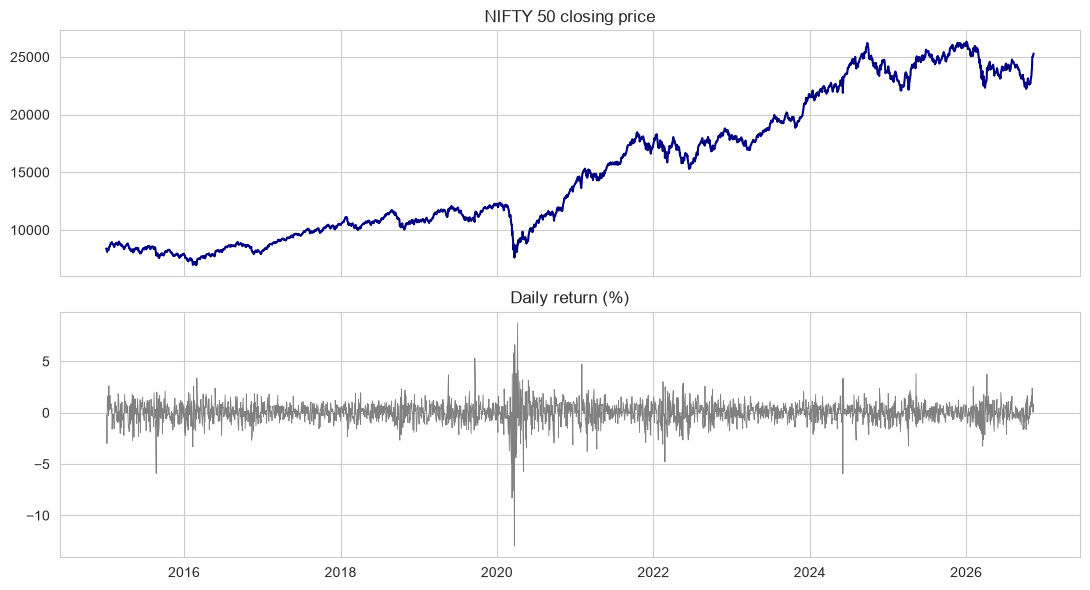

In [4]:
# 1b. Price and daily returns over time
nifty["ret"] = nifty["Close"].pct_change()          # daily return = today's close / yesterday's close - 1

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(nifty["Close"], color="navy")
ax[0].set_title("NIFTY 50 closing price")
ax[1].plot(nifty["ret"] * 100, color="gray", linewidth=0.6)
ax[1].set_title("Daily return (%)")
plt.tight_layout(); plt.show()

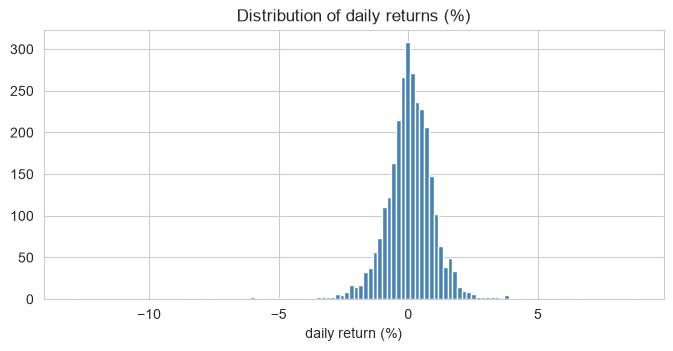

Mean 0.043%   Std 1.02%   Skew -0.99   Kurtosis 16.9
Worst day: -13.0% on 2020-03-23   Best day: 8.8% on 2020-04-07
Days with a move bigger than 3 std: 37  (a normal distribution would give about 7)


In [5]:
# 1c. How are daily returns distributed?
r = nifty["ret"].dropna() * 100
plt.figure(figsize=(8, 3.5))
plt.hist(r, bins=120, color="steelblue")
plt.title("Distribution of daily returns (%)"); plt.xlabel("daily return (%)"); plt.show()

print(f"Mean {r.mean():.3f}%   Std {r.std():.2f}%   Skew {r.skew():.2f}   Kurtosis {r.kurtosis():.1f}")
print(f"Worst day: {r.min():.1f}% on {r.idxmin().date()}   Best day: {r.max():.1f}% on {r.idxmax().date()}")
print(f"Days with a move bigger than 3 std: {(r.abs() > 3 * r.std()).sum()}  (a normal distribution would give about {int(len(r) * 0.0027)})")

UP days overall: 53.4%


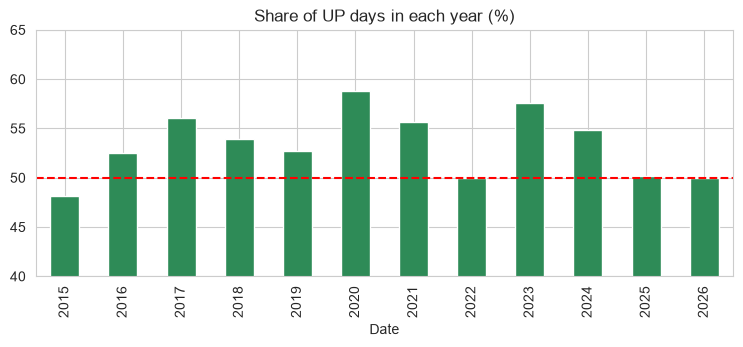

{2015: 48, 2016: 52, 2017: 56, 2018: 54, 2019: 53, 2020: 59, 2021: 56, 2022: 50, 2023: 58, 2024: 55, 2025: 50, 2026: 50}


In [6]:
# 1d. How many days are UP?
up = (r > 0)
print(f"UP days overall: {up.mean() * 100:.1f}%")

(up.groupby(up.index.year).mean() * 100).plot(kind="bar", figsize=(9, 3.2), color="seagreen")
plt.axhline(50, color="red", linestyle="--")
plt.title("Share of UP days in each year (%)"); plt.ylim(40, 65); plt.show()
print((up.groupby(up.index.year).mean() * 100).round(0).astype(int).to_dict())

In [7]:
# 1e. Does yesterday tell us about today?  (autocorrelation = correlation of a series with its own past)
auto = pd.DataFrame({
    "return vs its past": [r.autocorr(lag) for lag in range(1, 6)],
    "size of move vs its past": [r.abs().autocorr(lag) for lag in range(1, 6)],
}, index=[f"{lag} day(s) ago" for lag in range(1, 6)])
auto.round(3)

,return vs its past,size of move vs its past
1 day(s) ago,-0.024,0.259
2 day(s) ago,0.021,0.300
3 day(s) ago,0.013,0.260
4 day(s) ago,0.010,0.240
5 day(s) ago,0.053,0.206


Correlation of the day's return with the overnight part: 0.59
Correlation of the day's return with the intraday part : 0.78
Correlation between overnight part and intraday part   : -0.05
Correlation of NIFTY's return today with the S&P 500 move last night: 0.28
Correlation of NIFTY's return today with NIFTY's return yesterday   : -0.02


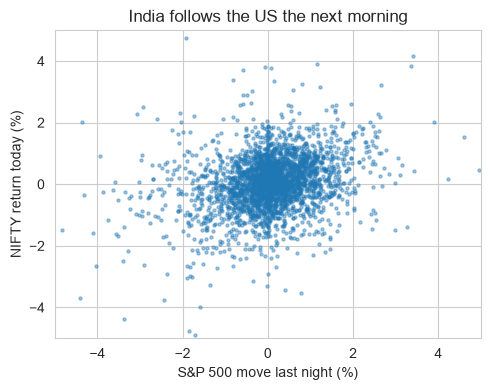

In [8]:
# 1f. Where does the day's move come from?
# A day's move has two parts:  overnight (yesterday's close -> today's open)  +  intraday (today's open -> close)
overnight = nifty["Open"] / nifty["Close"].shift(1) - 1
intraday = nifty["Close"] / nifty["Open"] - 1
print(f"Correlation of the day's return with the overnight part: {nifty['ret'].corr(overnight):.2f}")
print(f"Correlation of the day's return with the intraday part : {nifty['ret'].corr(intraday):.2f}")
print(f"Correlation between overnight part and intraday part   : {overnight.corr(intraday):.2f}")

def known_before_9am(series):
    # A US closing price of date D is known in India only on the morning of date D+1.
    # So: move every date forward by 1 day, then for each NIFTY day take the latest value available.
    s = series.copy()
    s.index = s.index + pd.Timedelta(days=1)
    return s.reindex(nifty.index, method="ffill")

sp500_last_night = known_before_9am(raw["sp500"]["Close"]).pct_change()     # US move since the previous NIFTY morning
print(f"Correlation of NIFTY's return today with the S&P 500 move last night: {nifty['ret'].corr(sp500_last_night):.2f}")
print(f"Correlation of NIFTY's return today with NIFTY's return yesterday   : {nifty['ret'].corr(nifty['ret'].shift(1)):.2f}")

plt.figure(figsize=(5.5, 4))
plt.scatter(sp500_last_night * 100, nifty["ret"] * 100, s=5, alpha=0.4)
plt.xlim(-5, 5); plt.ylim(-5, 5)
plt.xlabel("S&P 500 move last night (%)"); plt.ylabel("NIFTY return today (%)")
plt.title("India follows the US the next morning"); plt.show()

### What we found
| # | What we saw | Number | What we decided because of it |
|---|---|---|---|
| 1a | The data is clean. Only volume had errors. | 2,920 days, 0 missing, 0 duplicates, 28 zero-volume days | Replaced zero volume with the previous day's volume. |
| 1b | Price keeps climbing over the years. Returns stay around zero. | price went from about 7,000 to 26,000 | Use returns and ratios as features, never raw price. |
| 1c | Extreme days happen far more often than a normal curve predicts. | kurtosis 16.9, worst day -13.0% (23 Mar 2020), 37 days beyond 3 std (normal curve: about 7) | Cap the one known bad outlier (crude oil in 2020). Prefer models that are not thrown off by outliers. |
| 1d | UP and DOWN days are almost balanced, and the share changes by year. | 53.4% UP overall, between 48% and 59% in single years | No resampling needed. But "always UP" already gets about 53%, so we compare against baselines and use ROC-AUC. |
| 1e | Yesterday's **direction** says almost nothing about today. Yesterday's **size of move** does. | return autocorrelation about 0; size-of-move autocorrelation 0.21 to 0.30 | Expect a hard problem. Add volatility features. |
| 1f | A big part of the day's move is already decided **overnight**, and India follows the US. | correlation with overnight part 0.59; with last night's S&P 500 move 0.28; with yesterday's NIFTY return -0.02 | **This is the key finding.** Build features from what happens overnight. This is why we predict at 9:00 AM. |

**In one line:** NIFTY's own past says very little about today's direction, but last night's world markets say a lot.

# 2. Feature Derivation

**What:** we turn raw prices into **features**: numbers that describe the market at 9:00 AM.

**Why not give raw prices to the model?** NIFTY was near 8,000 in 2016 and is above 25,000 now. A model that learns "price = 8,000" learns nothing useful for today. Returns and ratios mean the same thing in every year, so we use only those.

**The features, in groups, with the reason for each:**

| Group | Features | Idea behind it |
|---|---|---|
| Momentum | `prev_ret_1`, `prev_ret_5`, `prev_ret_20` | Has the market been rising or falling lately? |
| Trend | `prev_vs_sma20`, `prev_vs_sma50`, `prev_vs_sma200` | Is price above or below its average of the last 20/50/200 days? |
| Overbought / oversold | `prev_rsi_14`, `prev_macd_hist` | Popular trader indicators. After a very fast rise, markets often pause. |
| Volatility | `prev_volatility_20`, `prev_range_14`, `prev_india_vix`, `prev_india_vix_change` | EDA showed calm and stormy periods come in groups. |
| Yesterday's candle | `prev_gap`, `prev_intraday_ret`, `prev_close_position` | How did yesterday open and close? Closing near the day's high shows buying strength. |
| Volume | `prev_volume_ratio` | Was yesterday's trading heavier than normal? |
| Long-term position | `prev_dist_52w_high` | How far are we below the 1-year high? |
| Banks | `prev_banknifty_ret` | Banks are the largest part of NIFTY. |
| Calendar | `day_of_week` | Monday has to absorb the whole weekend's news. |
| **Overnight (new)** | `sp500_night`, `nasdaq_night`, `usvix_night`, `crude_night`, `usdinr_night` | What happened in the US, oil and the rupee since the last Indian morning. |
| **Asia this morning (new)** | `nikkei_gap`, `hangseng_gap` | How did Japan and Hong Kong open today? |

**How we stop leakage:**
- Every NIFTY feature is calculated at the end of a day and then **shifted down by one row**. So the row for today only holds yesterday's values. That is why the names start with `prev_`.
- US values are moved forward by one calendar day before use (the function `known_before_9am` from Section 1f).
- For Asia we use only the **opening** gap, never the close, because their close comes after 9:00 AM India time.

**Why not use hundreds of technical indicators (for example from the `ta` library)?** Most indicators are built from the same price and say the same thing in different words. More copies of the same information only add noise. We keep a small set where each feature has a reason, and then remove near-duplicates with a correlation check.

**Why not news or Twitter sentiment?** There is no free, clean source of daily news history going back 10 years. And overnight price moves already contain the market's reaction to the news.

In [9]:
# ===== STEP 2: FEATURE DERIVATION =====
# 2a. Add one empty row for the next trading day. Its features will be ready (they all come from
#     the past), only the answer is unknown. We predict this row in Section 8c.
next_day = nifty.index[-1] + pd.offsets.BDay(1)
nifty.loc[next_day] = np.nan

close, open_, high, low, volume = nifty["Close"], nifty["Open"], nifty["High"], nifty["Low"], nifty["Volume"]

# 2b. NIFTY features, calculated at the END of each day
f = pd.DataFrame(index=nifty.index)
f["ret_1"] = close.pct_change()                                  # return of the last 1 day
f["ret_5"] = close.pct_change(5)                                 # ... last 5 days (one week)
f["ret_20"] = close.pct_change(20)                               # ... last 20 days (one month)
f["vs_sma20"] = close / close.rolling(20).mean() - 1             # distance from the 20-day average
f["vs_sma50"] = close / close.rolling(50).mean() - 1
f["vs_sma200"] = close / close.rolling(200).mean() - 1

change = close.diff()
avg_gain = change.clip(lower=0).rolling(14).mean()
avg_loss = (-change.clip(upper=0)).rolling(14).mean()
f["rsi_14"] = 100 - 100 / (1 + avg_gain / avg_loss)              # RSI: 0 to 100, above 70 = overbought

macd = close.ewm(span=12).mean() - close.ewm(span=26).mean()
f["macd_hist"] = (macd - macd.ewm(span=9).mean()) / close        # MACD histogram, divided by price

f["volatility_20"] = f["ret_1"].rolling(20).std()                # how jumpy the last 20 days were
f["range_14"] = ((high - low) / close).rolling(14).mean()        # average daily high-low range
f["gap"] = open_ / close.shift(1) - 1                            # opening gap
f["intraday_ret"] = close / open_ - 1                            # open -> close move
f["close_position"] = (close - low) / (high - low)               # 1 = closed at the day's high, 0 = at the low
f["volume_ratio"] = volume / volume.rolling(20).mean()           # volume compared to normal
f["dist_52w_high"] = close / close.rolling(252).max() - 1        # distance below the 1-year high

india_vix = raw["indiavix"]["Close"].reindex(nifty.index).ffill()
f["india_vix"] = india_vix
f["india_vix_change"] = india_vix.pct_change()
f["banknifty_ret"] = raw["banknifty"]["Close"].reindex(nifty.index).ffill().pct_change()

# 2c. SHIFT BY ONE DAY: today's row gets yesterday's values (this is the leakage guard)
df = f.shift(1).add_prefix("prev_")
df["day_of_week"] = df.index.dayofweek                           # 0 = Monday ... 4 = Friday

# 2d. Overnight features: what changed since the previous Indian morning
for name in ["sp500", "nasdaq", "usvix", "crude", "usdinr"]:
    df[name + "_night"] = known_before_9am(raw[name]["Close"]).pct_change()
df["crude_night"] = df["crude_night"].clip(-0.2, 0.2)            # oil went negative in April 2020: cap that outlier

# 2e. Asia this morning: opening gap of Japan and Hong Kong (0 if that market is closed today)
for name in ["nikkei", "hangseng"]:
    asia = raw[name]
    asia_gap = asia["Open"] / asia["Close"].shift(1) - 1
    df[name + "_gap"] = asia_gap.reindex(df.index).fillna(0)

OVERNIGHT = ["sp500_night", "nasdaq_night", "usvix_night", "crude_night", "usdinr_night", "nikkei_gap", "hangseng_gap"]
FEATURES = list(df.columns)
print("Number of features:", len(FEATURES))

# 2f. The answer (target). These three columns are NOT features.
df["today_ret"] = close.pct_change()                             # yesterday's close -> today's close
df["target"] = (df["today_ret"] > 0).astype(int)                 # 1 = UP, 0 = DOWN
df["open_to_close"] = close / open_ - 1                          # used only in the money check (Section 8b)

predict_row = df.iloc[[-1]]                # the next trading day: features ready, answer unknown
data = df.iloc[:-1].dropna()               # all finished days (first 252 days are lost to the 1-year window)
print("Usable days:", len(data), "| from", data.index.min().date(), "to", data.index.max().date())

Number of features: 26
Usable days: 2668 | from 2016-01-14 to 2026-11-12


### Train / test split

**What:** the first 80% of days are for training, the last 20% are for testing.

**Why split by time and not randomly?** A random split puts days from 2025 in training and days from 2023 in testing. The model would then "know the future" while being tested on the past. In real life we only ever have the past. So we train on the past and test on the future.

The test set is locked away. We open it only once, in Section 7. Every choice before that (features, regularization, tuning, final model) uses the training data only.

Train: 2016-01-14 to 2024-09-13 (2134 days), UP share 55.2%
Test : 2024-09-16 to 2026-11-12 (534 days), UP share 49.1%


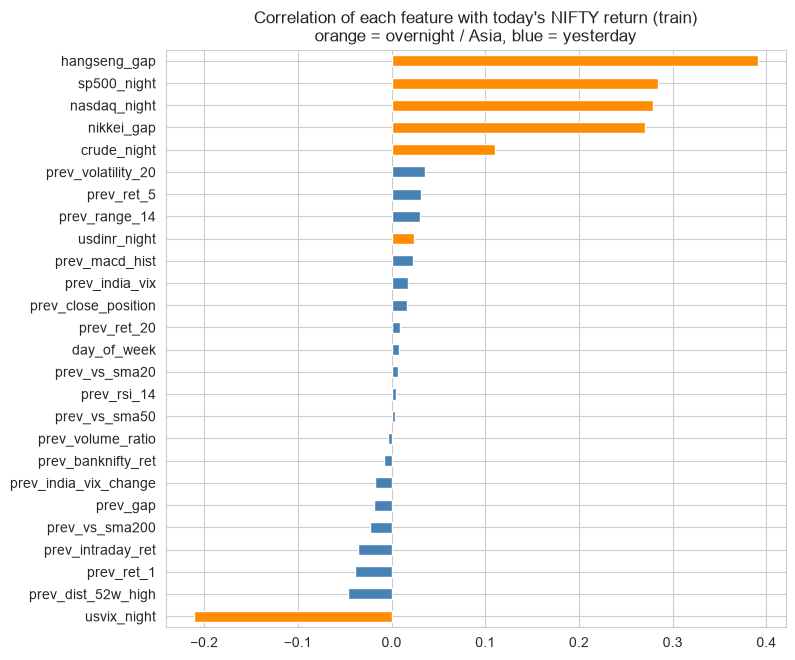

Strongest 6 features:
hangseng_gap    0.391
sp500_night     0.284
nasdaq_night    0.279
nikkei_gap      0.270
usvix_night    -0.211
crude_night     0.111
Largest correlation among the 'yesterday' features: 0.047


In [10]:
# 2g. Split by time: first 80% = train, last 20% = test
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]
print(f"Train: {train.index.min().date()} to {train.index.max().date()} ({len(train)} days), UP share {train['target'].mean() * 100:.1f}%")
print(f"Test : {test.index.min().date()} to {test.index.max().date()} ({len(test)} days), UP share {test['target'].mean() * 100:.1f}%")

# 2h. How strongly is each feature related to today's return?  (training data only)
corr_with_return = train[FEATURES].corrwith(train["today_ret"]).sort_values()
colors = ["darkorange" if c in OVERNIGHT else "steelblue" for c in corr_with_return.index]
corr_with_return.plot(kind="barh", figsize=(8, 7.5), color=colors)
plt.title("Correlation of each feature with today's NIFTY return (train)\norange = overnight / Asia, blue = yesterday")
plt.show()
print("Strongest 6 features:")
print(corr_with_return[corr_with_return.abs().sort_values(ascending=False).index[:6]].round(3).to_string())
print("Largest correlation among the 'yesterday' features:", round(corr_with_return.drop(OVERNIGHT).abs().max(), 3))

In [11]:
# 2i. Remove near-duplicate features: if two features have correlation above 0.9, keep only the first one
corr = train[FEATURES].corr().abs()
dropped = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        if corr.loc[a, b] > 0.9 and a not in dropped and b not in dropped:
            dropped.append(b)
            print(f"drop {b:22s} (correlation {corr.loc[a, b]:.2f} with {a})")

FEATURES = [c for c in FEATURES if c not in dropped]
OVERNIGHT = [c for c in OVERNIGHT if c in FEATURES]
print("\nFinal number of features:", len(FEATURES), "| of which overnight / Asia:", OVERNIGHT)

X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]

drop prev_range_14          (correlation 0.92 with prev_volatility_20)
drop nasdaq_night           (correlation 0.95 with sp500_night)

Final number of features: 24 | of which overnight / Asia: ['sp500_night', 'usvix_night', 'crude_night', 'usdinr_night', 'nikkei_gap', 'hangseng_gap']


### What we found
- We built **26 features**. After removing near-duplicates, **24 remain**:
  - `prev_range_14` was dropped (correlation 0.92 with `prev_volatility_20`). Both measure how jumpy the market is.
  - `nasdaq_night` was dropped (correlation 0.95 with `sp500_night`). Both measure the US market.
- **Why remove near-duplicates?** Two copies of the same information do not help the model. They only make the weights unstable and harder to read.
- **The chart confirms the EDA finding.** The strongest features are all overnight ones (orange): `hangseng_gap` 0.39, `sp500_night` 0.28, `nikkei_gap` 0.27, `usvix_night` -0.21. The sign of `usvix_night` makes sense: when US fear rises at night, NIFTY tends to fall the next day.
- The best "yesterday" feature (blue) has a correlation of only **0.047**. So each of them is weak alone. We keep them because a model can still combine many weak hints, and Section 7 tests whether they actually help.
- **Train:** 2,134 days (Jan 2016 to Sep 2024), 55.2% UP. **Test:** 534 days (Sep 2024 to Nov 2026), 49.1% UP. The test period was a weaker market than the training period. This is a real-life difficulty, and we will see its effect in Section 7.

# 3. Classification

**What:** we train a model that takes the features and gives the probability that today is an UP day.

### First, simple baselines (no machine learning)
A model is only useful if it beats simple rules. We use three:
- **Always UP:** say UP every day.
- **Same as yesterday:** if yesterday was UP, say UP.
- **Follow the US:** if the S&P 500 went up last night, say UP.

### Our main classifier: Logistic Regression
**How it works:**
1. Multiply each feature by a weight and add them up: `z = w1*x1 + w2*x2 + ... + b`
2. Pass `z` through the sigmoid function `1 / (1 + e^-z)`. This squeezes any number into the range 0 to 1, so we can read it as **P(UP)**.
3. If P(UP) > 0.5 we say UP, otherwise DOWN.
4. Training finds the weights that make the predicted probabilities match the real answers as closely as possible (it minimises **log-loss**).

**Why Logistic Regression first?**
- It is the standard starting model for a yes/no problem.
- It gives a probability, not just a label. We need that to know how confident the model is.
- Each weight can be read directly: a positive weight means "this feature pushes towards UP".
- It is simple, so it is hard to overfit. On noisy stock data this matters a lot.

**Why `StandardScaler` before it?** RSI goes from 0 to 100 but returns are around 0.01. Without scaling, the big-number features would dominate. Scaling puts every feature on the same scale (mean 0, std 1). The scaler sits inside a `Pipeline`, so it is fitted on training folds only (no leakage).

### How we judge a model without touching the test set
We use **time-series cross-validation** (`TimeSeriesSplit`, 5 folds): train on the first part, validate on the next part, then grow the training part and repeat. The model is always validated on days that come *after* its training days.

**Why not normal K-fold?** Normal K-fold would validate on days that lie *between* training days, which again lets the model see the future.

**Why ROC-AUC as the main score?** Accuracy can look fine just by saying UP every day. AUC asks a better question: does the model give higher probabilities to real UP days than to real DOWN days? 0.5 = random, 1.0 = perfect.

In [12]:
# ===== STEP 3: CLASSIFICATION =====
# 3a. Simple baselines
def baseline_predictions(d):
    return {
        "Baseline: always UP": np.ones(len(d), dtype=int),
        "Baseline: same as yesterday": (d["prev_ret_1"] > 0).astype(int).values,
        "Baseline: follow the US (S&P up last night)": (d["sp500_night"] > 0).astype(int).values,
    }

for name, pred in baseline_predictions(train).items():
    print(f"{name:45s} accuracy on train period: {accuracy_score(y_train, pred) * 100:.1f}%")

Baseline: always UP                           accuracy on train period: 55.2%
Baseline: same as yesterday                   accuracy on train period: 53.7%
Baseline: follow the US (S&P up last night)   accuracy on train period: 60.0%


Logistic Regression: {'Train AUC': 0.702, 'Validation AUC': 0.661, 'Validation accuracy %': 60.4}


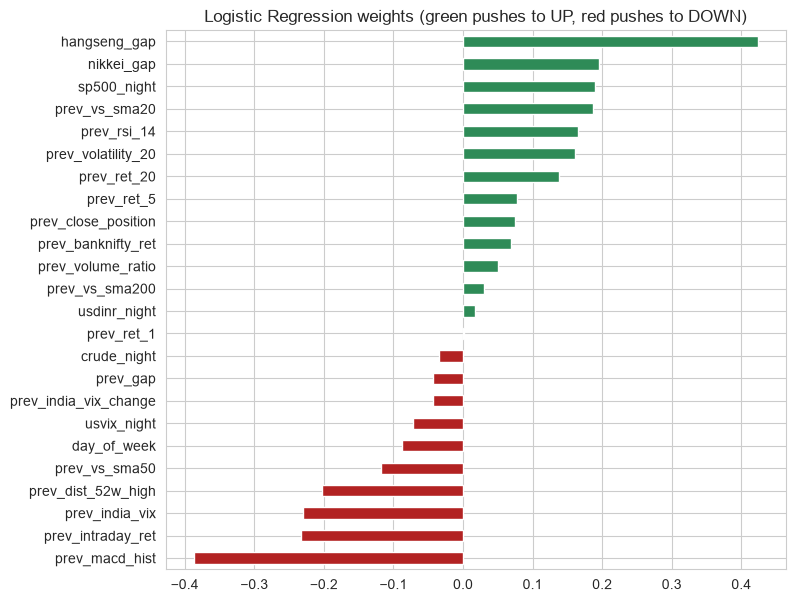

Six biggest weights:
hangseng_gap          0.42
prev_macd_hist       -0.39
prev_intraday_ret    -0.23
prev_india_vix       -0.23
prev_dist_52w_high   -0.20
nikkei_gap            0.20


In [13]:
# 3b. Logistic Regression, checked with time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5)

def check_model(model):
    # Train on the past, validate on the next block of days, 5 times. Returns the average scores.
    s = cross_validate(model, X_train, y_train, cv=tscv, scoring=["roc_auc", "accuracy"], return_train_score=True)
    return {"Train AUC": round(float(s["train_roc_auc"].mean()), 3),
            "Validation AUC": round(float(s["test_roc_auc"].mean()), 3),
            "Validation accuracy %": round(float(s["test_accuracy"].mean()) * 100, 1)}

# C = 1000 means "almost no regularization". We add regularization in Section 4.
log_reg = make_pipeline(StandardScaler(), LogisticRegression(C=1000, max_iter=5000))
print("Logistic Regression:", check_model(log_reg))

# Look inside the model: which features got the biggest weights?
log_reg.fit(X_train, y_train)
weights = pd.Series(log_reg[-1].coef_[0], index=FEATURES).sort_values()
weights.plot(kind="barh", figsize=(8, 7), color=["firebrick" if w < 0 else "seagreen" for w in weights])
plt.title("Logistic Regression weights (green pushes to UP, red pushes to DOWN)"); plt.show()
print("Six biggest weights:")
print(weights[weights.abs().sort_values(ascending=False).index[:6]].round(2).to_string())

### Why not another classifier?
Instead of only arguing, we test the other common classifier families on the same data, with their normal settings.

| Model | Idea | Our worry before testing |
|---|---|---|
| **KNN** | Find the 15 most similar past days and copy their answer. | With 20+ features, "similar" days are hard to find (curse of dimensionality). |
| **Naive Bayes** | Assumes all features are independent. | Our features are clearly related to each other (all come from the same prices). |
| **Decision Tree** | Asks a chain of yes/no questions. | A full tree memorises the training data. |
| **SVM (RBF kernel)** | Draws a curved boundary between UP and DOWN. | Flexible, so it can fit noise. Gives no natural probability. |

In [14]:
# 3c. Compare classifier families (normal settings, same cross-validation)
candidates = {
    "Logistic Regression": log_reg,
    "KNN (k = 15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Naive Bayes": GaussianNB(),
    "Decision Tree (no limits)": DecisionTreeClassifier(random_state=SEED),
    "SVM (RBF kernel)": make_pipeline(StandardScaler(), SVC()),
}
pd.DataFrame({name: check_model(model) for name, model in candidates.items()}).T

,Train AUC,Validation AUC,Validation accuracy %
Logistic Regression,0.702,0.661,60.4
KNN (k = 15),0.717,0.598,57.3
Naive Bayes,0.672,0.650,62.5
Decision Tree (no limits),1.000,0.549,55.0
SVM (RBF kernel),0.831,0.640,60.9


### What we found
**Baselines (training period):** always UP 55.2%, same as yesterday 53.7%, follow the US 60.0%. So any model must beat **60%** to be worth using. "Same as yesterday" is worse than "always UP", which matches the EDA (yesterday's direction is useless).

**Logistic Regression:** validation AUC **0.661**, validation accuracy 60.4%. Training AUC is 0.702, so there is a small gap between train and validation: a little overfitting, which Section 4 reduces.

**Reading the weights:** the biggest positive weights are `hangseng_gap` (+0.42) and `nikkei_gap` (+0.20): if Asia opens higher, NIFTY tends to end the day UP. The negative weights (`prev_macd_hist`, `prev_intraday_ret`, `prev_india_vix`) say that after a strong run or in a fearful market, the next day is a little more likely to be DOWN.

**Why not the other classifiers? The table gives the answer:**

| Model | Validation AUC | What happened |
|---|---|---|
| **Logistic Regression** | **0.661** | Best. Small gap between train and validation. |
| Naive Bayes | 0.650 | Surprisingly close. But it assumes features are independent (ours are not), it cannot be regularized, and its probabilities are less reliable. |
| SVM (RBF) | 0.640 | Train 0.831 but validation 0.640. The flexible boundary fitted noise. |
| KNN | 0.598 | "Similar days" in 24 dimensions are not really similar. |
| Decision Tree (no limits) | 0.549 | Train AUC **1.000**, validation 0.549. It memorised the training data. A clear picture of overfitting. |

So the simplest model wins on this data. The Decision Tree result also tells us that trees **must** be controlled, which is the job of the next three sections.

# 4. Regularization

**The problem:** stock data is mostly noise. A model that is free to do anything will memorise the noise of the training days. Then it scores high on training data and low on new data. This is **overfitting**. We saw it in Section 3: the full Decision Tree had a perfect training score and a poor validation score.

**What regularization does:** it adds a penalty for being too complex. The model must now have a good reason to use a feature strongly.

### For Logistic Regression: L1 and L2
We add a penalty on the size of the weights to the loss:
- **L2 (Ridge):** penalty = sum of `w²`. It shrinks all weights towards zero, but keeps every feature.
- **L1 (Lasso):** penalty = sum of `|w|`. It pushes useless weights to **exactly zero**, so it also selects features.

The strength is set by `C`. **Small C = strong regularization.** Large C = almost none.

### For trees: limit the size
- `max_depth`: how many questions a tree may ask in a row.
- `min_samples_leaf`: a final group must contain at least this many days. This stops the tree from making a rule for 2 or 3 special days.

**Why these and not Dropout or early stopping?** Dropout is for neural networks, which we do not use. Early stopping needs an extra validation set for boosting; limiting tree depth and learning rate gives the same control and is simpler to explain. Elastic Net (a mix of L1 and L2) adds one more knob; we first check whether L1 and L2 differ at all.

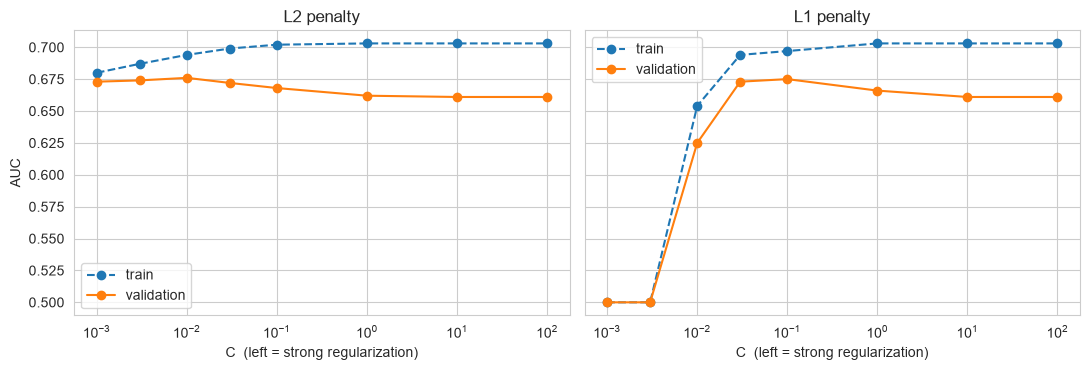

Train AUC        Validation AUC        Features kept      
Penalty        L1     L2             L1     L2            L1    L2
C                                                                 
0.001       0.500  0.680          0.500  0.673           0.0  24.0
0.003       0.500  0.687          0.500  0.674           0.0  24.0
0.010       0.654  0.694          0.625  0.676           3.0  24.0
0.030       0.694  0.699          0.673  0.672           7.0  24.0
0.100       0.697  0.702          0.675  0.668          15.0  24.0
1.000       0.703  0.703          0.666  0.662          21.0  24.0
10.000      0.703  0.703          0.661  0.661          24.0  24.0
100.000     0.703  0.703          0.661  0.661          24.0  24.0

In [15]:
# ===== STEP 4: REGULARIZATION =====
# 4a. Logistic Regression: L2 vs L1, from very strong (small C) to almost none (large C)
#     In scikit-learn: l1_ratio = 0 means L2, l1_ratio = 1 means L1.
rows = []
for penalty, ratio in [("L2", 0), ("L1", 1)]:
    for C in [0.001, 0.003, 0.01, 0.03, 0.1, 1, 10, 100]:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, l1_ratio=ratio, solver="liblinear", max_iter=1000))
        scores = check_model(model)
        model.fit(X_train, y_train)
        features_kept = (model[-1].coef_[0] != 0).sum()
        rows.append([penalty, C, scores["Train AUC"], scores["Validation AUC"], features_kept])
reg_table = pd.DataFrame(rows, columns=["Penalty", "C", "Train AUC", "Validation AUC", "Features kept"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for i, penalty in enumerate(["L2", "L1"]):
    t = reg_table[reg_table["Penalty"] == penalty]
    ax[i].plot(t["C"], t["Train AUC"], "o--", label="train")
    ax[i].plot(t["C"], t["Validation AUC"], "o-", label="validation")
    ax[i].set_xscale("log"); ax[i].set_xlabel("C  (left = strong regularization)")
    ax[i].set_title(penalty + " penalty"); ax[i].legend()
ax[0].set_ylabel("AUC"); plt.tight_layout(); plt.show()
reg_table.pivot(index="C", columns="Penalty", values=["Train AUC", "Validation AUC", "Features kept"])

In [16]:
# 4b. Which features does L1 keep when it is strict?  (the first C where at least 3 features survive)
for C in [0.003, 0.01, 0.03, 0.1]:
    lasso = make_pipeline(StandardScaler(), LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=1000)).fit(X_train, y_train)
    kept = pd.Series(lasso[-1].coef_[0], index=FEATURES)
    kept = kept[kept != 0]
    if len(kept) >= 3:
        print(f"L1 with C = {C} keeps {len(kept)} of {len(FEATURES)} features:")
        print(kept.sort_values().round(3).to_string())
        break

L1 with C = 0.01 keeps 3 of 24 features:
sp500_night     0.068
nikkei_gap      0.126
hangseng_gap    0.266


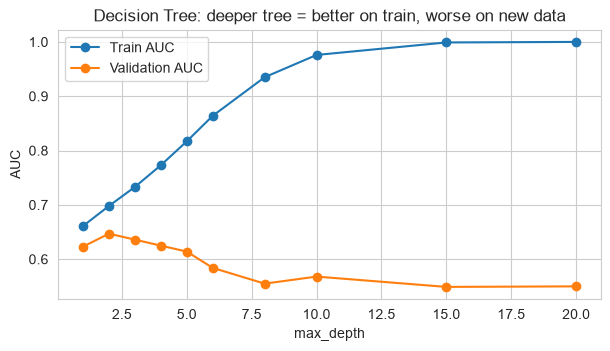

max_depth,1,2,3,4,5,6,8,10,15,20
Train AUC,0.661,0.698,0.733,0.773,0.817,0.864,0.935,0.976,0.999,1.00
Validation AUC,0.623,0.647,0.636,0.625,0.614,0.584,0.555,0.568,0.549,0.55


In [17]:
# 4c. Decision Tree: what happens as we allow deeper trees?
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]:
    scores = check_model(DecisionTreeClassifier(max_depth=depth, random_state=SEED))
    rows.append([depth, scores["Train AUC"], scores["Validation AUC"]])
depth_table = pd.DataFrame(rows, columns=["max_depth", "Train AUC", "Validation AUC"]).set_index("max_depth")

depth_table.plot(marker="o", figsize=(7, 3.5))
plt.title("Decision Tree: deeper tree = better on train, worse on new data"); plt.ylabel("AUC"); plt.show()
depth_table.T

### What we found
**Logistic Regression**
- **L2 helps.** With almost no regularization (C = 100) validation AUC is 0.661. With strong L2 (C = 0.01) it rises to **0.676**. At the same time the training AUC falls from 0.703 to 0.694. So the gap between train and validation shrinks from 0.042 to 0.018: less memorising, better on new data.
- **L1 selects features.** At C = 0.03 it keeps only **7 of 24** features and still scores 0.673. At C = 0.01 it keeps just 3: `hangseng_gap`, `nikkei_gap` and `sp500_night`. So L1 itself tells us which features carry the signal.
- **Too much regularization is also bad.** With L1 at C = 0.003 or lower, every weight becomes zero and the AUC drops to 0.500 (pure guessing). This is **underfitting**.
- **L1 vs L2:** their best scores are almost the same (0.675 vs 0.676). Because of that, Elastic Net (a mix of the two) would not add anything, so we did not use it.

**Decision Tree**
- Training AUC climbs with depth all the way to 1.000. Validation AUC is best at **depth 2 (0.647)** and then falls to 0.55 at depth 20.
- This is the overfitting curve in its simplest form: more freedom gives a better score on old data and a worse score on new data.

**What we take forward:** on this noisy data, simple and strongly regularized models are better. The tuning in Section 5 should therefore choose small `C`, shallow trees and large leaves. We will check whether it does.

# 5. Hyperparameter Tuning

**Parameters vs hyperparameters:**
- A **parameter** is learned by the model from data (for example the weights of Logistic Regression).
- A **hyperparameter** is a setting we choose *before* training (for example `C`, or the depth of a tree). The model cannot learn it by itself.

**What:** for each model we try a small grid of settings and keep the one with the best **validation AUC**.

**How:** `GridSearchCV` tries every combination in the grid. Each combination is scored with the same time-series cross-validation as before.

| Model | Hyperparameter | What it controls |
|---|---|---|
| Logistic Regression | `C` | Regularization strength (small = strong). |
| | `l1_ratio` | 0 = L2 penalty, 1 = L1 penalty. |
| Decision Tree | `max_depth` | How complex one tree can be. |
| | `min_samples_leaf` | Minimum days in a final group. Bigger = smoother. |
| Random Forest | `max_depth`, `min_samples_leaf` | Same as above, for every tree in the forest. |
| XGBoost | `n_estimators` | Number of trees added one after another. |
| | `max_depth` | Size of each small tree. |
| | `learning_rate` | How much each new tree is allowed to change the answer. Small = careful. |

**Why Grid Search and not Random Search or Bayesian optimisation (Optuna)?** Our grids are small (8 to 18 combinations), so we can afford to try all of them. Grid search is simple, fully repeatable, and easy to explain. Random and Bayesian search are useful when there are thousands of combinations.

**Why tune on validation data and not on the test set?** If we pick settings by looking at the test score, the test set is no longer "unseen" and the final score becomes too optimistic.

In [18]:
# ===== STEP 5: HYPERPARAMETER TUNING =====
searches = {
    "Logistic Regression": (
        make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", max_iter=1000)),
        {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1], "logisticregression__l1_ratio": [0, 1]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [20, 50, 100]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
        {"max_depth": [3, 5, 8, 12], "min_samples_leaf": [5, 20, 50, 100]}),
    "XGBoost": (
        XGBClassifier(subsample=0.8, colsample_bytree=0.8, random_state=SEED),
        {"n_estimators": [100, 300], "max_depth": [2, 3, 4], "learning_rate": [0.01, 0.05, 0.1]}),
}

best_models, results, rows = {}, {}, []
for name, (model, grid) in searches.items():
    before = check_model(model)["Validation AUC"]                       # with default settings
    search = GridSearchCV(model, grid, cv=tscv, scoring="roc_auc", return_train_score=True)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_                           # already re-trained on all training data
    results[name] = pd.DataFrame(search.cv_results_)
    best = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
    rows.append([name, before, round(search.best_score_, 3), str(best)])

tuning_table = pd.DataFrame(rows, columns=["Model", "Validation AUC (default)", "Validation AUC (tuned)", "Best settings"]).set_index("Model")
pd.set_option("display.max_colwidth", 100)
tuning_table

,Validation AUC (default),Validation AUC (tuned),Best settings
Model,,,
Logistic Regression,0.662,0.676,"{'C': 0.01, 'l1_ratio': 0}"
Decision Tree,0.549,0.648,"{'max_depth': 3, 'min_samples_leaf': 100}"
Random Forest,0.665,0.673,"{'max_depth': 8, 'min_samples_leaf': 20}"
XGBoost,0.624,0.669,"{'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}"


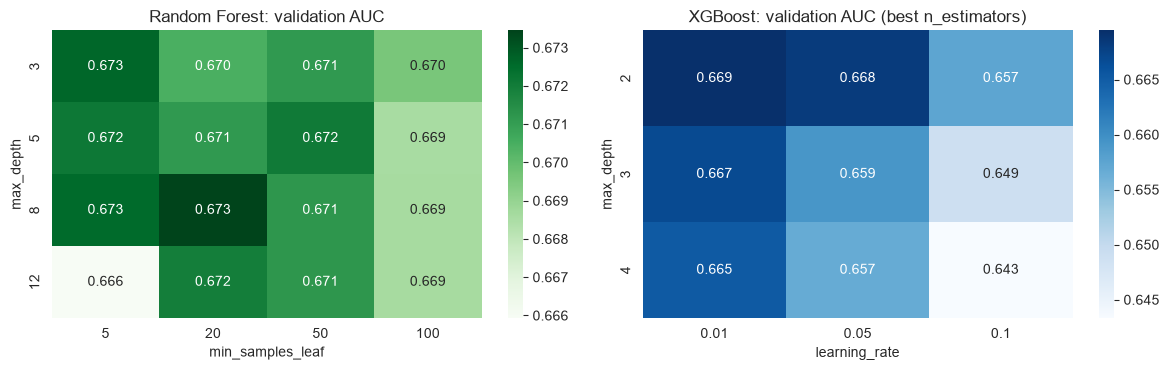

In [19]:
# 5b. How much does each setting matter?  Validation AUC for every combination (Random Forest and XGBoost)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
rf = results["Random Forest"].pivot(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score")
sns.heatmap(rf, annot=True, fmt=".3f", cmap="Greens", ax=ax[0])
ax[0].set_title("Random Forest: validation AUC"); ax[0].set_xlabel("min_samples_leaf"); ax[0].set_ylabel("max_depth")

xgb = results["XGBoost"].groupby(["param_max_depth", "param_learning_rate"])["mean_test_score"].max().unstack()
sns.heatmap(xgb, annot=True, fmt=".3f", cmap="Blues", ax=ax[1])
ax[1].set_title("XGBoost: validation AUC (best n_estimators)"); ax[1].set_xlabel("learning_rate"); ax[1].set_ylabel("max_depth")
plt.tight_layout(); plt.show()

### What we found
| Model | Default settings | After tuning | Best settings |
|---|---|---|---|
| Logistic Regression | 0.662 | **0.676** | C = 0.01, L2 |
| Decision Tree | 0.549 | 0.648 | max_depth = 3, min_samples_leaf = 100 |
| Random Forest | 0.665 | 0.673 | max_depth = 8, min_samples_leaf = 20 |
| XGBoost | 0.624 | 0.669 | learning_rate = 0.01, max_depth = 2, n_estimators = 100 |

**What the tuning teaches us:**
- **Every model improved**, and the models that overfit most by default improved most (Decision Tree +0.10, XGBoost +0.045).
- **The winners are the careful settings**, exactly as Section 4 predicted: strong regularization for Logistic Regression, a shallow tree with big leaves, and for XGBoost the smallest depth and the smallest learning rate in the grid.
- **XGBoost is sensitive.** In its heatmap the score falls from 0.669 (depth 2, learning rate 0.01) to 0.643 (depth 4, learning rate 0.1). Deeper trees and bigger steps fit noise faster.
- **Random Forest is not sensitive.** All 16 of its combinations lie between 0.666 and 0.673. Averaging 300 trees already controls overfitting, so the exact settings matter little. This is a useful property: it is hard to tune a Random Forest badly.
- After tuning, all models are close together (0.648 to 0.676). The data sets the limit here, not the choice of algorithm.

# 6. Ensemble Techniques

**Idea:** one model makes mistakes. Many different models make *different* mistakes. If we combine them, the mistakes partly cancel out. It is like asking many people instead of one.

We use three kinds of ensemble:

| Type | Model | How it works | What it fixes |
|---|---|---|---|
| **Bagging** | Random Forest | Builds 300 trees. Each tree sees a random sample of days and a random subset of features. The trees vote. | **Variance:** a single tree changes a lot when the data changes a little. Averaging many trees makes the answer stable. |
| **Boosting** | XGBoost | Builds small trees one after another. Each new tree focuses on the days the earlier trees got wrong. | **Bias:** a single small tree is too simple. Adding many of them builds a stronger model step by step. |
| **Voting** | LR + RF + XGBoost | Takes the average P(UP) of three different kinds of model ("soft" voting). | A linear model and tree models see the data differently, so their errors differ. |

Random Forest and XGBoost were already tuned in Section 5. Here we add the Voting ensemble and compare everything against a **single** Decision Tree, to see what ensembles add.

**Why these two tree ensembles?** They are the standard choices for table-shaped data, and they represent the two main ideas (bagging and boosting).

**Why XGBoost and not AdaBoost, LightGBM or CatBoost?** They are all boosting. XGBoost is the most widely used and has built-in regularization. LightGBM is mainly faster on huge datasets (ours has about 2,000 rows) and CatBoost is mainly for categorical features (we have almost none).

**Why soft voting and not hard voting?** Hard voting counts only the labels (UP/DOWN). Soft voting averages the probabilities, so a model that is very sure counts more than a model that is 51% sure.

**Why not Stacking?** Stacking trains one more model on top of the others. It needs predictions made on held-out data, which is easy to get wrong with time-ordered data and can leak. Voting gives most of the benefit with no extra training step.

**Why not a neural network / LSTM?** Deep models need a lot of data. We have about 2,000 training days with a weak signal. A network with thousands of weights would memorise them. Tree ensembles are the usual winner on small table-shaped data.

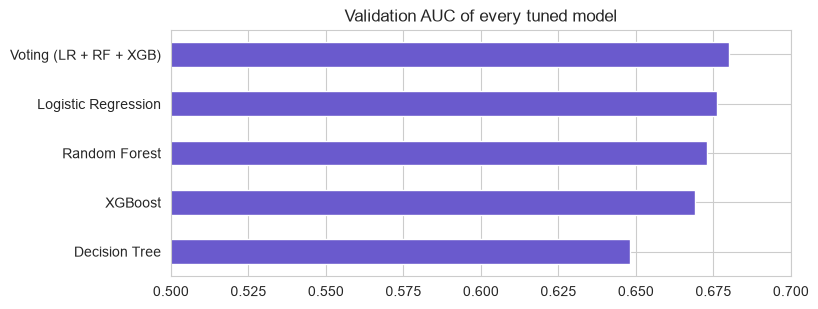

Decision Tree             0.648
XGBoost                   0.669
Random Forest             0.673
Logistic Regression       0.676
Voting (LR + RF + XGB)    0.680

Final model: Voting (LR + RF + XGB)


In [20]:
# ===== STEP 6: ENSEMBLES =====
voting = VotingClassifier(
    estimators=[("lr", clone(best_models["Logistic Regression"])),
                ("rf", clone(best_models["Random Forest"])),
                ("xgb", clone(best_models["XGBoost"]))],
    voting="soft")                                   # soft = average the probabilities
voting_scores = check_model(voting)
best_models["Voting (LR + RF + XGB)"] = voting.fit(X_train, y_train)

validation_auc = tuning_table["Validation AUC (tuned)"].to_dict()
validation_auc["Voting (LR + RF + XGB)"] = voting_scores["Validation AUC"]
validation_auc = pd.Series(validation_auc).sort_values()

validation_auc.plot(kind="barh", figsize=(8, 3.2), color="slateblue")
plt.xlim(0.5, validation_auc.max() + 0.02); plt.title("Validation AUC of every tuned model"); plt.show()
print(validation_auc.round(3).to_string())

# The final model is chosen by VALIDATION score. The test set has still not been used.
final_name = validation_auc.idxmax()
final_model = best_models[final_name]
print("\nFinal model:", final_name)

### What we found
| Model | Type | Validation AUC |
|---|---|---|
| Decision Tree | single model | 0.648 |
| XGBoost | boosting | 0.669 |
| Random Forest | bagging | 0.673 |
| Logistic Regression | single model | 0.676 |
| **Voting (LR + RF + XGB)** | voting | **0.680** |

- **Ensembles of trees beat a single tree:** 0.648 → 0.673 (bagging) and 0.669 (boosting). This is the main reason to use them.
- **Bagging is slightly ahead of boosting here.** Our data is noisy, so the main problem is variance, and reducing variance is what bagging does. Boosting keeps correcting its "mistakes", but on noisy data many of those mistakes are just noise.
- **Voting is the best of all (0.680).** It combines a linear model with two tree models. They make different errors, so the average is a little better than each one alone.
- The gain from voting is small (+0.004 over Logistic Regression). We say that honestly. The practical benefit is stability: the final answer does not depend on one model.
- **Final model: Voting (LR + RF + XGB)**, chosen by validation AUC. The test set was not used for this choice.

# 7. Performance Analysis

Now, and only now, we open the **test set**: the most recent 20% of days, which no model has seen and no decision has used.

**The metrics, in plain words:**

| Metric | Question it answers |
|---|---|
| **Accuracy** | Out of all days, how many did we get right? |
| **Precision** | When we said UP, how often was it really UP? |
| **Recall** | Out of all real UP days, how many did we catch? |
| **F1** | One number that balances precision and recall. |
| **ROC-AUC** | Does the model give higher P(UP) to real UP days than to real DOWN days? (0.5 = random) |

**Why so many metrics?** Each one can be fooled alone. "Always UP" gets 100% recall. A model that says UP only once and is right gets 100% precision. We look at them together, and always next to the baselines.

**Why not just report accuracy?** Because of the above, and because accuracy ignores *how sure* the model is. AUC and the confidence table (7d) use the probabilities.

In [21]:
# ===== STEP 7: PERFORMANCE ANALYSIS =====
# 7a. Every model and every baseline on the test set
rows = []
for name, model in best_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba > 0.5).astype(int)
    rows.append([name,
                 accuracy_score(y_train, model.predict(X_train)) * 100,
                 accuracy_score(y_test, pred) * 100,
                 precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred),
                 roc_auc_score(y_test, proba)])
for name, pred in baseline_predictions(test).items():
    rows.append([name, np.nan, accuracy_score(y_test, pred) * 100,
                 precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred), np.nan])

performance = pd.DataFrame(rows, columns=["Model", "Train accuracy %", "Test accuracy %", "Precision", "Recall", "F1", "ROC-AUC"]).set_index("Model")
print("Final model (chosen in Section 6 by validation score):", final_name)
performance.round(3)

Final model (chosen in Section 6 by validation score): Voting (LR + RF + XGB)


,Train accuracy %,Test accuracy %,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,64.386,58.052,0.553,0.752,0.638,0.630
Decision Tree,65.886,56.554,0.541,0.752,0.629,0.614
Random Forest,74.367,58.427,0.560,0.718,0.629,0.636
XGBoost,65.698,58.240,0.552,0.794,0.651,0.631
Voting (LR + RF + XGB),69.447,58.614,0.556,0.775,0.648,0.635
Baseline: always UP,NaN,49.064,0.491,1.000,0.658,NaN
Baseline: same as yesterday,NaN,53.371,0.525,0.523,0.524,NaN
Baseline: follow the US (S&P up last night),NaN,57.303,0.561,0.599,0.579,NaN


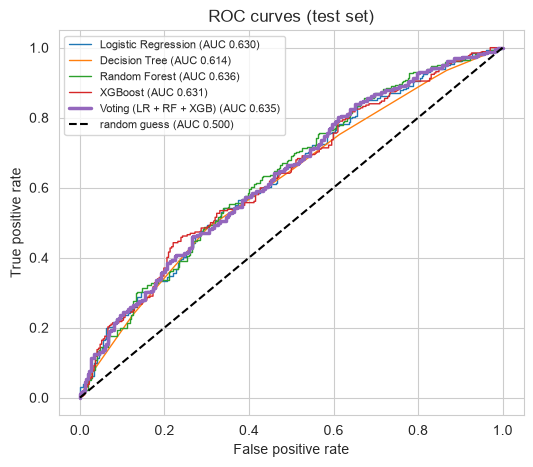

In [22]:
# 7b. ROC curves on the test set
plt.figure(figsize=(6, 5))
for name, model in best_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})", linewidth=2.5 if name == final_name else 1)
plt.plot([0, 1], [0, 1], "k--", label="random guess (AUC 0.500)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)")
plt.legend(fontsize=8); plt.show()

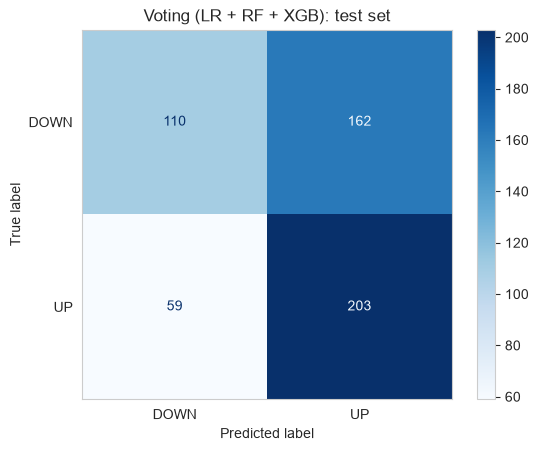

The model said UP on 68% of test days. Real UP days: 49%.
Said UP and was right: 203   Said UP and was wrong: 162
Said DOWN and was right: 110   Said DOWN and was wrong: 59


In [23]:
# 7c. Confusion matrix of the final model
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba > 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["DOWN", "UP"], cmap="Blues")
plt.title(f"{final_name}: test set"); plt.grid(False); plt.show()
print(f"The model said UP on {test_pred.mean() * 100:.0f}% of test days. Real UP days: {y_test.mean() * 100:.0f}%.")
print(f"Said UP and was right: {((test_pred == 1) & (y_test == 1)).sum()}   Said UP and was wrong: {((test_pred == 1) & (y_test == 0)).sum()}")
print(f"Said DOWN and was right: {((test_pred == 0) & (y_test == 0)).sum()}   Said DOWN and was wrong: {((test_pred == 0) & (y_test == 1)).sum()}")

In [24]:
# 7d. Is the model more accurate when it is more sure?
#     confidence = how far P(UP) is from 0.5
confidence = np.abs(test_proba - 0.5)
rows = []
for level in [0.00, 0.05, 0.10, 0.15, 0.20]:
    sure = confidence >= level
    rows.append([f"P(UP) above {0.5 + level:.2f} or below {0.5 - level:.2f}", sure.sum(), round(sure.mean() * 100),
                 round(accuracy_score(y_test[sure], test_pred[sure]) * 100, 1)])
pd.DataFrame(rows, columns=["Only days where", "Days", "% of all test days", "Accuracy %"])

,Only days where,Days,% of all test days,Accuracy %
0,P(UP) above 0.50 or below 0.50,534,100,58.6
1,P(UP) above 0.55 or below 0.45,393,74,60.3
2,P(UP) above 0.60 or below 0.40,241,45,63.9
3,P(UP) above 0.65 or below 0.35,130,24,70.8
4,P(UP) above 0.70 or below 0.30,49,9,77.6


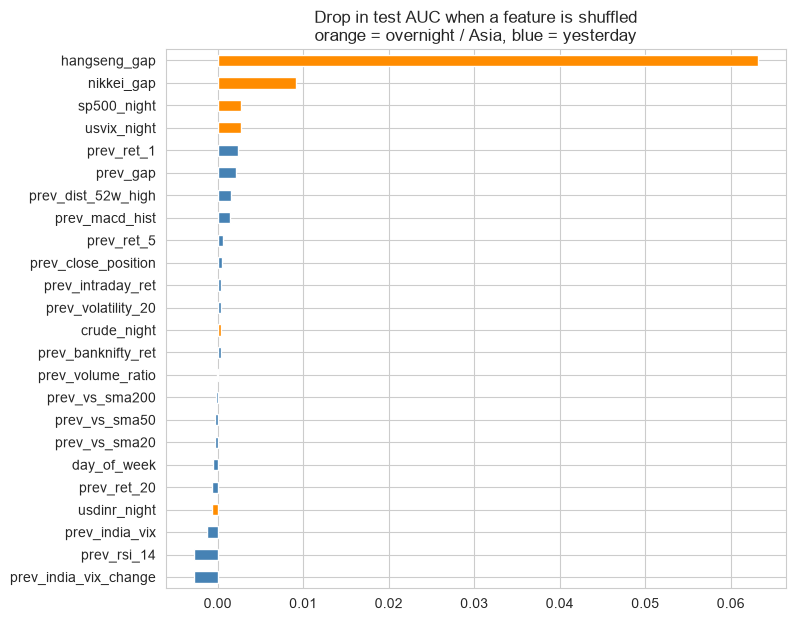

Six most important features (drop in AUC):
hangseng_gap    0.063
nikkei_gap      0.009
sp500_night     0.003
usvix_night     0.003
prev_ret_1      0.002
prev_gap        0.002
All 'yesterday' features together: 0.001 | all overnight / Asia features together: 0.077


In [25]:
# 7e. Which features does the final model really use?
#     Permutation importance: shuffle one feature and see how much the test AUC drops.
imp = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
colors = ["darkorange" if c in OVERNIGHT else "steelblue" for c in importance.index]
importance.plot(kind="barh", figsize=(8, 7), color=colors)
plt.title("Drop in test AUC when a feature is shuffled\norange = overnight / Asia, blue = yesterday"); plt.show()
print("Six most important features (drop in AUC):")
print(importance.sort_values(ascending=False).head(6).round(3).to_string())
print("All 'yesterday' features together:", round(importance.drop(OVERNIGHT).sum(), 3), "| all overnight / Asia features together:", round(importance[OVERNIGHT].sum(), 3))

In [26]:
# 7f. Proof that the overnight features are what makes the model work:
#     train the SAME final model again, but WITHOUT the overnight / Asia features.
YESTERDAY_ONLY = [c for c in FEATURES if c not in OVERNIGHT]
old_style = clone(final_model).fit(X_train[YESTERDAY_ONLY], y_train)
old_proba = old_style.predict_proba(X_test[YESTERDAY_ONLY])[:, 1]

pd.DataFrame({
    "Features": [len(YESTERDAY_ONLY), len(FEATURES)],
    "Test accuracy %": [accuracy_score(y_test, old_proba > 0.5) * 100, accuracy_score(y_test, test_pred) * 100],
    "Test ROC-AUC": [roc_auc_score(y_test, old_proba), roc_auc_score(y_test, test_proba)],
}, index=["Only yesterday's information (like predicting the evening before)", "With overnight + Asia information (9:00 AM)"]).round(3)

,Features,Test accuracy %,Test ROC-AUC
Only yesterday's information (like predicting the evening before),18,50.562,0.521
With overnight + Asia information (9:00 AM),24,58.614,0.635


### What we found
**Result of the final model on the unseen test set (Sep 2024 to Nov 2026, 534 days):**

| | Accuracy | ROC-AUC |
|---|---|---|
| **Final model: Voting** | **58.6%** | **0.635** |
| Baseline: follow the US | 57.3% | - |
| Baseline: same as yesterday | 53.4% | - |
| Baseline: always UP | 49.1% | - |

**Interpretation**
- **The model beats every baseline**, and all five models land between 56.6% and 58.6%. The models agree with each other, which is a sign the result is real and not luck of one model.
- **But the lead over "follow the US" is small (1.3 points).** A large part of the model's skill is the simple fact that India follows world markets. The model adds a little on top by also using Asia's opening and by giving a probability.
- **Validation predicted the test honestly.** The ranking of models is nearly the same on validation and on test, and no model collapsed. Test AUC (0.635) is lower than validation AUC (0.680) because the test period was a harder, sideways market.
- **Overfitting check:** train accuracy is 69.4% and test accuracy is 58.6% for the final model. Random Forest has the biggest gap (74.4% vs 58.4%), Logistic Regression the smallest (64.4% vs 58.1%).
- **Confusion matrix:** the model said UP on 68% of days, but only 49% were UP. It learned an UP habit from a rising training period (55% UP). So its DOWN calls are better (110 right, 59 wrong = 65%) than its UP calls (203 right, 162 wrong = 56%). This is why precision (0.56) is lower than recall (0.78).
- **Confidence matters (7d).** When P(UP) is above 0.60 or below 0.40 (45% of days), accuracy is **63.9%**. Above 0.65 or below 0.35 (24% of days) it is **70.8%**. So the probability is meaningful: the model knows when it knows. The last row (77.6%) has only 49 days, so we do not lean on it.
- **Which features matter (7e).** Shuffling `hangseng_gap` drops the AUC by 0.063. The other five overnight features together add about 0.014. All 18 "yesterday" features together add about 0.001. So the model is mostly reading **how Asia opened this morning**.
- **Proof (7f).** The same model without the overnight and Asia features gets **50.6%** accuracy and AUC 0.521, which is a coin toss. With them it gets 58.6% and 0.635. **The gain comes from feature derivation, not from a cleverer algorithm.**

# 8. Real-life use

The test set is one period of about two years. Three more checks tell us how the model behaves in real use.

### 8a. Walk-forward check, year by year
**What:** we copy how the model would really be used. Start in 2019. Train on everything before that day, predict the next 63 trading days (about 3 months), then add those days to the training data and repeat.

**Why:** one test period can be lucky or unlucky. This gives a score for every year from 2019, including the 2020 crash.

**One honest note:** the model settings were tuned on data up to the split date, which overlaps most of these years. So the years before the split are slightly flattered. The years after the split are fully clean.

### 8b. Honest money check
A direction model is not automatically a money-making model. We check what a trader could really do with the 9:00 AM signal.

### 8c. Signal for the next trading day
We train on all data and predict the row we added in Section 2a.

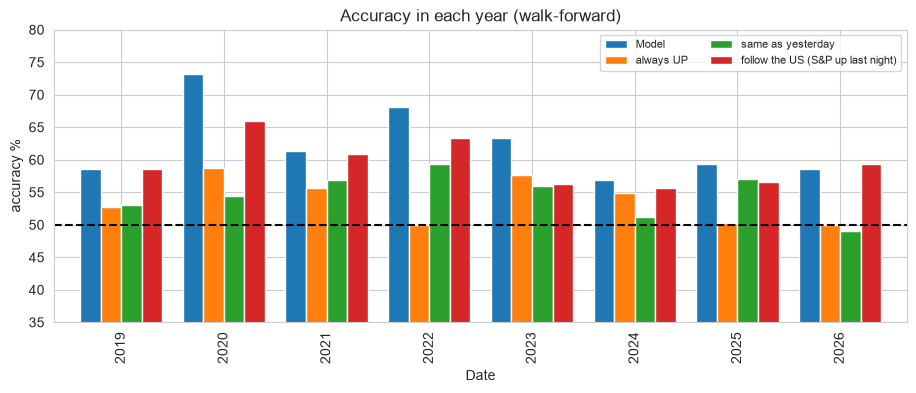

Walk-forward 2019-01-02 to 2026-11-12: 1939 days, ROC-AUC 0.662
Confident days (P(UP) above 0.60 or below 0.40): 49% of days, accuracy 70.2%


,Model,always UP,same as yesterday,follow the US (S&P up last night)
Date,,,,
2019,58.5,52.7,53.1,58.5
2020,73.2,58.8,54.4,66.0
2021,61.3,55.6,56.9,60.9
2022,68.1,50.0,59.3,63.3
2023,63.3,57.6,55.9,56.3
2024,56.9,54.9,51.2,55.7
2025,59.4,50.2,57.0,56.6
2026,58.5,50.0,49.1,59.4
All years,62.5,53.8,54.7,59.6


In [27]:
# ===== STEP 8: REAL-LIFE USE =====
# 8a. Walk-forward: re-train every 63 trading days, always using only the past
X_all, y_all = data[FEATURES], data["target"]
start = data.index.searchsorted(pd.Timestamp("2019-01-01"))

wf_proba = []
for s in range(start, len(data), 63):
    e = min(s + 63, len(data))
    model = clone(final_model).fit(X_all.iloc[:s], y_all.iloc[:s])        # train on the past only
    wf_proba.extend(model.predict_proba(X_all.iloc[s:e])[:, 1])           # predict the next 3 months

wf = data.iloc[start:].copy()
wf["proba"] = wf_proba
wf["pred"] = (wf["proba"] > 0.5).astype(int)

by_year = pd.DataFrame({"Model": (wf["pred"] == wf["target"])})
for name, pred in baseline_predictions(wf).items():
    by_year[name.replace("Baseline: ", "")] = (pred == wf["target"])
yearly = (by_year.groupby(by_year.index.year).mean() * 100).round(1)
yearly.loc["All years"] = (by_year.mean() * 100).round(1)

yearly.drop("All years").plot(kind="bar", figsize=(11, 3.8), width=0.8)
plt.axhline(50, color="black", linestyle="--"); plt.ylim(35, 80)
plt.title("Accuracy in each year (walk-forward)"); plt.ylabel("accuracy %"); plt.legend(fontsize=8, ncol=2); plt.show()
print(f"Walk-forward {wf.index.min().date()} to {wf.index.max().date()}: {len(wf)} days, ROC-AUC {roc_auc_score(wf['target'], wf['proba']):.3f}")
sure = np.abs(wf["proba"] - 0.5) >= 0.10
print(f"Confident days (P(UP) above 0.60 or below 0.40): {sure.mean() * 100:.0f}% of days, accuracy {(wf['pred'] == wf['target'])[sure].mean() * 100:.1f}%")
yearly

### 8b. Honest money check

Our target is "today's close vs **yesterday's** close". But at 9:00 AM, yesterday's close is gone. The market opens at 9:15 at a **new** price, which already includes the overnight news (the opening gap).

So a trader can only buy at **today's open** and sell at **today's close**. The real question is: on days when the model says UP, does NIFTY rise **from open to close**?

On days the model says UP vs DOWN (walk-forward period):
  close-to-close return (our target, NOT tradeable): UP days +0.281%   DOWN days -0.343%
  open-to-close return  (what a trader can get)     : UP days -0.027%   DOWN days -0.101%
  accuracy for the open-to-close direction: 51.0%


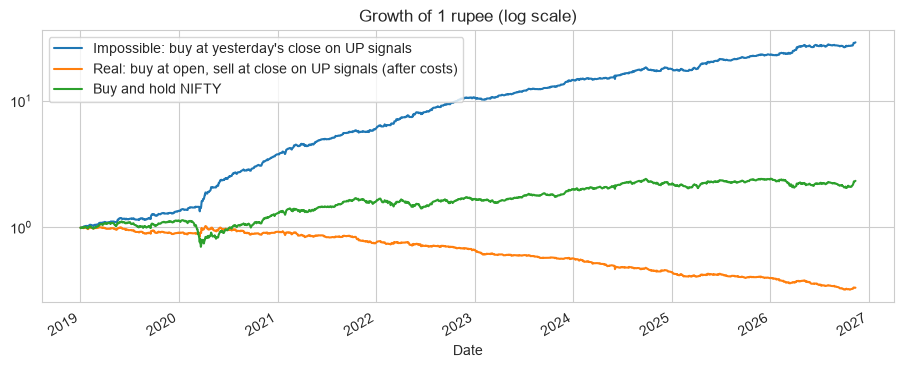

,1 rupee becomes
Impossible: buy at yesterday's close on UP signals,28.99
"Real: buy at open, sell at close on UP signals (after costs)",0.33
Buy and hold NIFTY,2.33


In [28]:
# 8b. What can actually be traded?
says_up = wf["pred"] == 1
print("On days the model says UP vs DOWN (walk-forward period):")
print(f"  close-to-close return (our target, NOT tradeable): UP days {wf.loc[says_up, 'today_ret'].mean() * 100:+.3f}%   DOWN days {wf.loc[~says_up, 'today_ret'].mean() * 100:+.3f}%")
print(f"  open-to-close return  (what a trader can get)     : UP days {wf.loc[says_up, 'open_to_close'].mean() * 100:+.3f}%   DOWN days {wf.loc[~says_up, 'open_to_close'].mean() * 100:+.3f}%")
print(f"  accuracy for the open-to-close direction: {((wf['open_to_close'] > 0) == says_up).mean() * 100:.1f}%")

COST = 0.0003 * 2                                                        # about 0.03% to buy + 0.03% to sell
impossible = np.where(says_up, wf["today_ret"], 0)                       # needs buying at yesterday's close AFTER seeing the news
real = np.where(says_up, wf["open_to_close"] - COST, 0)                  # buy at open, sell at close, pay costs
curves = pd.DataFrame({
    "Impossible: buy at yesterday's close on UP signals": (1 + impossible).cumprod(),
    "Real: buy at open, sell at close on UP signals (after costs)": (1 + real).cumprod(),
    "Buy and hold NIFTY": (1 + wf["today_ret"]).cumprod(),
}, index=wf.index)
curves.plot(figsize=(11, 4)); plt.yscale("log"); plt.title("Growth of 1 rupee (log scale)"); plt.show()
(curves.iloc[-1]).round(2).to_frame("1 rupee becomes")

In [29]:
# 8c. Signal for the next trading day (run between 7:30 and 9:00 AM with REFRESH_DATA = True for a live signal)
live_model = clone(final_model).fit(X_all, y_all)                        # use every finished day
p_up = live_model.predict_proba(predict_row[FEATURES])[0, 1]

print("Last finished day in the data:", data.index.max().date())
print("Prediction for the next trading day:", predict_row.index[0].date())
print("Overnight inputs (%):", (predict_row[OVERNIGHT].iloc[0] * 100).round(2).to_dict())
if (predict_row[["nikkei_gap", "hangseng_gap"]].iloc[0] == 0).all():
    print("Note: Asian opening gaps are 0 (Asia has not opened yet for that day), so this signal is weaker than a morning run.")
print(f"\nP(UP) = {p_up:.2f}")
if p_up >= 0.60:
    print("Signal: UP (confident)")
elif p_up <= 0.40:
    print("Signal: DOWN (confident)")
else:
    print("Signal: NOT SURE (probability is between 0.40 and 0.60)")

Last finished day in the data: 2026-11-12
Prediction for the next trading day: 2026-11-13
Overnight inputs (%): {'sp500_night': -0.35, 'usvix_night': 6.92, 'crude_night': 2.55, 'usdinr_night': -0.24, 'nikkei_gap': 0.0, 'hangseng_gap': 0.0}
Note: Asian opening gaps are 0 (Asia has not opened yet for that day), so this signal is weaker than a morning run.

P(UP) = 0.49
Signal: NOT SURE (probability is between 0.40 and 0.60)


### What we found
**8a. Year by year (2019 to 2026, 1,939 days, re-trained every 3 months)**

| | Model | Follow the US | Same as yesterday | Always UP |
|---|---|---|---|---|
| All years | **62.5%** | 59.6% | 54.7% | 53.8% |

- The model is at or above the best baseline in **7 of 8 years**, and never below 56.9%. The exception is 2026, where "follow the US" is slightly ahead (59.4% vs 58.5%). In 2019 the two are equal (58.5%).
- Its best year is 2020 (73.2%). In a crisis, all markets move together, so overnight news explains more.
- The recent years (2024 to 2026) are lower, about 57% to 59%. That matches the test result of 58.6%. For the future, **58% to 60% is the fair number to expect**, not 62%.
- On confident days (P(UP) above 0.60 or below 0.40, about half of all days) accuracy is **70.2%**.

**8b. Honest money check**
- On days the model says UP, the close-to-close return is +0.28% on average, and on DOWN days -0.34%. This is the skill we measured.
- **But this cannot be traded.** By 9:15 AM the market has already opened at a new price that includes the overnight news. From open to close, the average return is about **-0.03% on UP days** and -0.10% on DOWN days, and the model gets the open-to-close direction right only **51.0%** of the time.
- The chart shows it clearly. The "impossible" strategy turns 1 rupee into 29. The real strategy (buy at open, sell at close, pay costs) turns 1 rupee into 0.33. Buy and hold gives 2.33.
- **Why?** Thousands of traders see the same overnight news. They push the opening price to the right level within the first seconds. This is called an **efficient market**: public news is already in the price.
- DOWN days do show a small negative drift after the open (-0.10%). It is about the size of trading costs and we could not test it with real futures prices, so we do not claim it as a strategy.

**So what is the model good for?**
- It tells an investor, before the market opens, **which way the day is likely to end and how sure the model is**. That helps to set expectations and to avoid panic at the open.
- It is **not** a tool for making money by day trading, and we do not present it as one.

**8c.** The last cell gives the signal for the next trading day. For a real morning signal, set `REFRESH_DATA = True` in Section 0 and run the notebook between 7:30 and 9:00 AM, after Hong Kong has opened. Without the Asian opening values the signal is much weaker, because that is the model's most important input.

# 9. Conclusion

**What we built:** a model that predicts at 9:00 AM whether NIFTY 50 will close above yesterday's close.

**Main results**

| | Number |
|---|---|
| Accuracy on the unseen test set (Sep 2024 to Nov 2026) | **58.6%** (best simple rule: 57.3%, always UP: 49.1%) |
| Accuracy over 8 years of walk-forward testing (2019 to 2026) | **62.5%** (best simple rule: 59.6%) |
| Accuracy on days when the model is confident | **about 64% to 70%** |
| Same model without overnight features | 50.6% (coin toss) |

**What we learned**
1. **Feature derivation mattered more than the algorithm.** Changing the prediction time from the previous evening to 9:00 AM, and adding overnight features, moved accuracy from about 51% to about 59%. No change of algorithm did anything close to that.
2. **Simple, regularized models won.** Every tuned model chose its most careful settings. An unlimited Decision Tree scored 1.000 on training data and 0.549 on validation.
3. **Ensembles helped, a little.** Tree ensembles clearly beat a single tree. Voting gave the best validation score.
4. **Honest validation is the most important skill.** Time-based split, time-series cross-validation, a test set used only once, and comparison with simple baselines. Without these, it is easy to report 80% or 90% and be wrong.
5. **Predicting direction is not the same as making money.** The model has real skill, but the opening price already contains the news it uses.

**Limitations**
- The lead over the simple rule "follow the US" is small (about 1 to 3 points).
- The model leans towards UP because it was trained in a rising market.
- It depends heavily on one input (Hong Kong's opening). If that relationship weakens, the model weakens.
- Yahoo Finance data is free but not perfect; index opening values are calculated, not traded prices.

**What we would do next**
- Add GIFT Nifty (NIFTY futures that trade at night). It is the most direct pre-market signal, but there is no free history for it.
- Add FII/DII flows and options data (put-call ratio).
- Predict the **size** of the move (volatility) instead of the direction. EDA showed that this is much more predictable.

---

## Quick viva questions

**Q: Why classification and not regression?**
We want UP or DOWN. Predicting the exact price mostly gives "same as yesterday", which looks accurate and is useless.

**Q: What is data leakage, and how did you avoid it?**
Leakage is using information that would not be available at prediction time. We avoided it in six ways: (1) all NIFTY features are shifted by one day, (2) US data is used only from the morning after, (3) only the opening gap of Asian markets is used, (4) the train/test split is by time, (5) cross-validation is `TimeSeriesSplit`, (6) the scaler is inside the pipeline, and near-duplicate features were found using training data only.

**Q: Is the Hong Kong opening really known at 9:00 AM India time?**
Yes. Hong Kong opens at 9:30 AM its time, which is 7:00 AM in India. Japan opens at 5:30 AM India time.

**Q: Why not shuffle the data before splitting?**
Shuffling puts future days in the training set. In real life we only have the past.

**Q: Why ROC-AUC and not only accuracy?**
"Always UP" gets about 53% accuracy without learning anything. AUC checks whether real UP days get higher probabilities than real DOWN days, at every threshold.

**Q: Difference between L1 and L2?**
L1 adds the sum of |w| to the loss and sets useless weights to exactly zero (feature selection). L2 adds the sum of w² and shrinks all weights smoothly. Here both gave almost the same score; L2 with C = 0.01 was chosen.

**Q: What does C mean?**
C is the inverse of regularization strength. Small C = strong penalty = simpler model.

**Q: Parameter vs hyperparameter?**
A parameter is learned from data (weights). A hyperparameter is set by us before training (C, tree depth, learning rate).

**Q: Bagging vs boosting?**
Bagging trains many trees separately on random samples and averages them: it reduces variance. Boosting trains small trees one after another, each fixing the earlier errors: it reduces bias. On noisy data variance is the bigger problem, so bagging was slightly ahead.

**Q: Why did you choose Voting as the final model?**
It had the highest validation AUC (0.680). The choice was made before looking at the test set.

**Q: Random Forest had a slightly higher test AUC. Why not pick it?**
Choosing by test score turns the test set into a second validation set, and the reported number becomes too optimistic. Model choice must use validation data only.

**Q: Your accuracy is about 59%. Is that good?**
For daily market direction, yes. Markets are close to efficient, so an honest result is only a few points above 50%. Our own check shows that without overnight information the same model is at 50.6%. Results of 80% to 90% in this area almost always come from leakage.

**Q: Can this model make money?**
Not by itself. It predicts close versus yesterday's close, but a trader can only buy at today's open, and the open already contains the overnight news. From open to close the model is right only 51% of the time.

**Q: Why not LSTM or deep learning?**
About 2,000 training days and a weak signal are far too little for a deep network. Our results also show that simpler models did better than flexible ones.

**Q: What is walk-forward validation?**
Train on all past data, predict the next 3 months, add those months to the training data, and repeat. It copies how the model would be used in real life.

**Q: What is permutation importance?**
Shuffle one feature so it becomes meaningless and measure how much the score drops. A big drop means the model depended on that feature.